In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Classes:", data.target_names)

Train: (455, 30) Test: (114, 30)
Classes: ['malignant' 'benign']


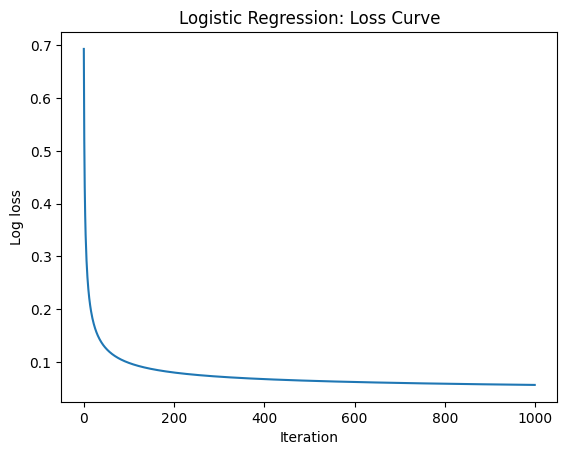

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))   # clip avoids overflow

class MyLogisticRegression:
    def __init__(self, lr=0.1, epochs=1000):
        self.lr = lr                # learning rate (step size)
        self.epochs = epochs        # number of iterations

    def fit(self, X, y):
        m, n = X.shape              # m = samples, n = features
        self.w = np.zeros(n)        # start weights at 0
        self.b = 0                  # start bias at 0
        self.losses = []
        for _ in range(self.epochs):
            p = sigmoid(X @ self.w + self.b)            # 1. predicted probability
            dw = (1/m) * X.T @ (p - y)                  # 2. gradient for weights
            db = (1/m) * np.sum(p - y)                  # 3. gradient for bias
            self.w -= self.lr * dw                      # 4. update weights
            self.b -= self.lr * db                      #    update bias
            loss = -np.mean(y*np.log(p + 1e-9) + (1-y)*np.log(1-p + 1e-9))
            self.losses.append(loss)

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

log_reg = MyLogisticRegression(lr=0.1, epochs=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

plt.plot(log_reg.losses)
plt.xlabel("Iteration")
plt.ylabel("Log loss")
plt.title("Logistic Regression: Loss Curve")
plt.show()

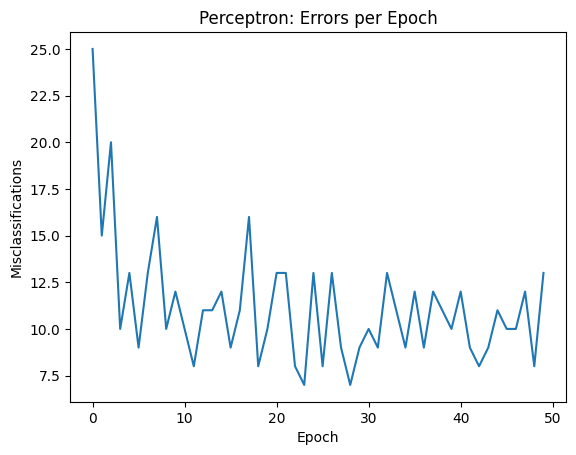

In [4]:
class MyPerceptron:
    def __init__(self, lr=0.1, epochs=50):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0
        self.errors = []
        for _ in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):                         # one sample at a time
                pred = 1 if (xi @ self.w + self.b) >= 0 else 0   # step function
                update = self.lr * (target - pred)               # perceptron rule
                self.w += update * xi
                self.b += update
                errors += int(update != 0)                       # count mistakes
            self.errors.append(errors)

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

perc = MyPerceptron(lr=0.1, epochs=50)
perc.fit(X_train, y_train)
y_pred_p = perc.predict(X_test)

plt.plot(perc.errors)
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Perceptron: Errors per Epoch")
plt.show()

In [5]:
def evaluate(name, y_true, y_pred):
    print(f"{name}")
    print(f"  Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"  Recall   : {recall_score(y_true, y_pred):.4f}")
    print(f"  F1-Score : {f1_score(y_true, y_pred):.4f}\n")

evaluate("Logistic Regression", y_test, y_pred_lr)
evaluate("Perceptron", y_test, y_pred_p)

Logistic Regression
  Accuracy : 0.9737
  Precision: 0.9859
  Recall   : 0.9722
  F1-Score : 0.9790

Perceptron
  Accuracy : 0.9649
  Precision: 0.9857
  Recall   : 0.9583
  F1-Score : 0.9718



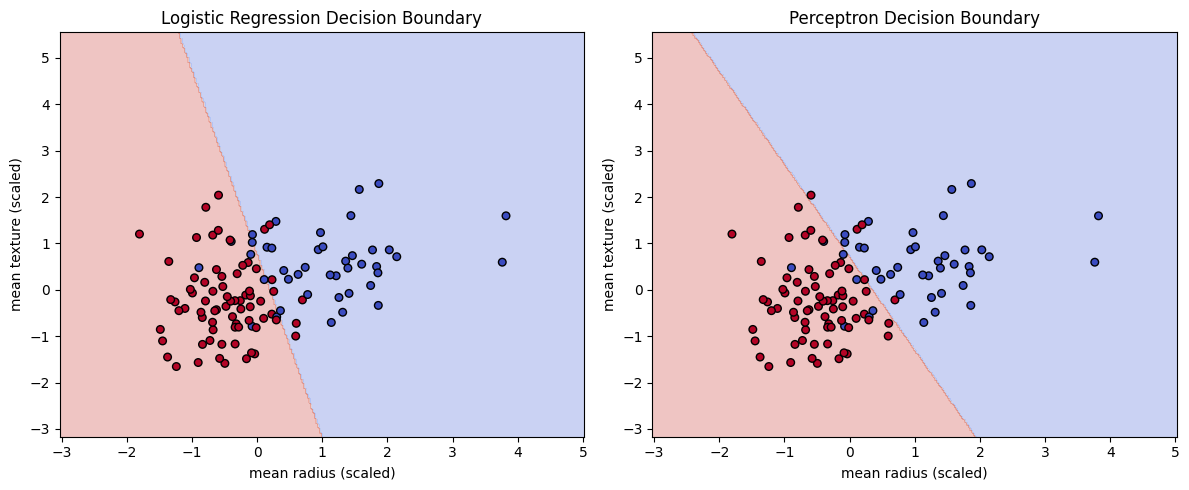

Accuracy with 2 features -> LogReg: 0.8771929824561403
Accuracy with 2 features -> Perceptron: 0.9035087719298246


In [6]:
# Pick 2 features: mean radius (0) and mean texture (1)
f1_idx, f2_idx = 0, 1
X2_train = X_train[:, [f1_idx, f2_idx]]
X2_test = X_test[:, [f1_idx, f2_idx]]

# Retrain both models on only these 2 features
lr2 = MyLogisticRegression(lr=0.1, epochs=1000)
lr2.fit(X2_train, y_train)

p2 = MyPerceptron(lr=0.1, epochs=50)
p2.fit(X2_train, y_train)

# Make a grid covering the whole plot area
x_min, x_max = X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1
y_min, y_max = X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in zip(axes, [lr2, p2], ["Logistic Regression", "Perceptron"]):
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")          # coloured regions
    ax.scatter(X2_test[:, 0], X2_test[:, 1], c=y_test,
               cmap="coolwarm", edgecolor="k", s=30)            # test points
    ax.set_xlabel(data.feature_names[f1_idx] + " (scaled)")
    ax.set_ylabel(data.feature_names[f2_idx] + " (scaled)")
    ax.set_title(title + " Decision Boundary")

plt.tight_layout()
plt.show()

print("Accuracy with 2 features -> LogReg:", accuracy_score(y_test, lr2.predict(X2_test)))
print("Accuracy with 2 features -> Perceptron:", accuracy_score(y_test, p2.predict(X2_test)))